DAY 11: PERTURBATION SENSITIVITY
Rayleigh number: 2500.0

Running perturbation A = 0.005
Steps: 3332
Final time: 0.025
Maximum velocity: 491.5800162988717
Bottom Nu: 9.787178344487458
Top Nu: 11.660332162494926

Running perturbation A = 0.015
Steps: 3340
Final time: 0.025
Maximum velocity: 488.31934604630914
Bottom Nu: 9.746131680907636
Top Nu: 12.4540519764337

Running perturbation A = 0.03
Steps: 3374
Final time: 0.025
Maximum velocity: 499.1082015202058
Bottom Nu: 10.17225794850293
Top Nu: 12.498508097377691

Summary saved: day11_perturbation_results\day11_perturbation_summary.csv


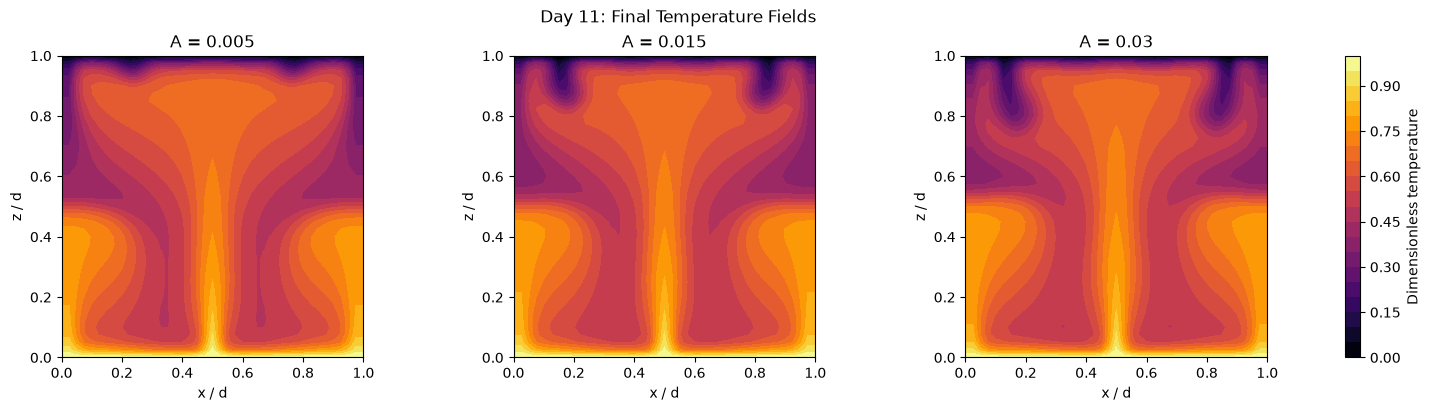

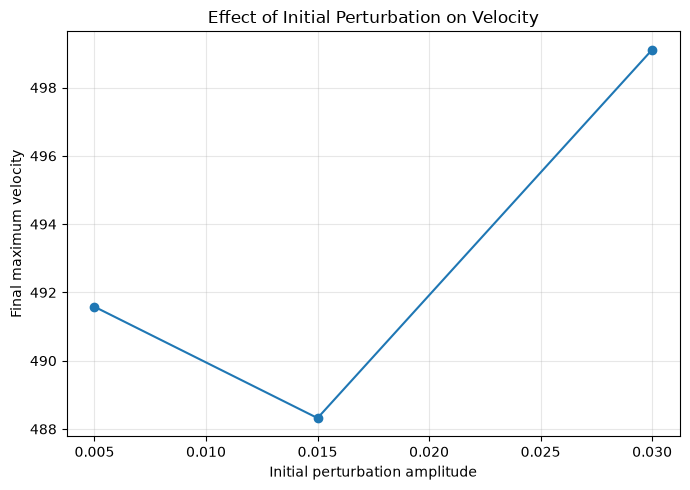

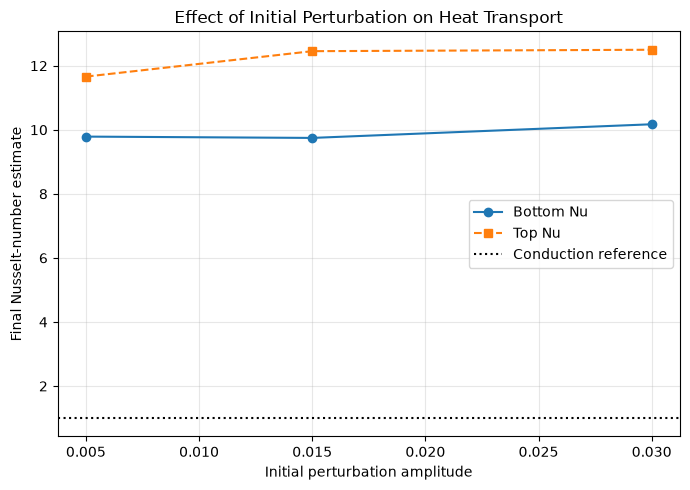

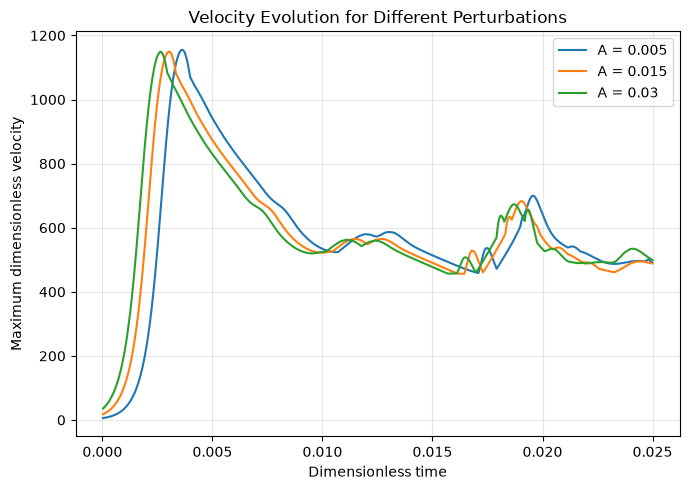


DAY 11 COMPLETED
Output folder: C:\Users\athil\OneDrive\Desktop\day11_perturbation_results
Files generated:
1. day11_perturbation_summary.csv
2. day11_temperature_comparison.png
3. day11_velocity_comparison.png
4. day11_nusselt_comparison.png
5. day11_velocity_vs_time.png

Interpret the results only after checking numerical stability.
This simplified model is not a validated mantle-flow solver.


In [1]:
"""
DAY 11: INITIAL PERTURBATION SENSITIVITY

Project: 2-D Numerical Modelling of Mantle Convection

Objectives:
1. Compare different initial temperature perturbations.
2. Compare maximum velocity and Nusselt estimates.
3. Plot final temperature fields.
4. Save a CSV summary.

Required libraries:
pip install numpy scipy matplotlib
"""

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import factorized


# ============================================================
# 1. SETTINGS
# ============================================================

RA = 2500.0
N = 41
END_TIME = 0.025

PERTURBATIONS = [0.005, 0.015, 0.030]

DT_SAFETY = 0.20
MAX_STEPS = 200000

OUTPUT_DIR = Path("day11_perturbation_results")
OUTPUT_DIR.mkdir(exist_ok=True)

print("DAY 11: PERTURBATION SENSITIVITY")
print("Rayleigh number:", RA)


# ============================================================
# 2. GRID
# ============================================================

def make_grid(n):

    x = np.linspace(0, 1, n)
    z = np.linspace(0, 1, n)

    X, Z = np.meshgrid(x, z)

    dx = x[1] - x[0]
    dz = z[1] - z[0]

    return x, z, X, Z, dx, dz


# ============================================================
# 3. DERIVATIVES
# ============================================================

def laplacian(T, dx, dz):

    result = np.zeros_like(T)

    result[1:-1, 1:-1] = (
        (T[1:-1, 2:] - 2*T[1:-1, 1:-1]
         + T[1:-1, :-2]) / dx**2
        +
        (T[2:, 1:-1] - 2*T[1:-1, 1:-1]
         + T[:-2, 1:-1]) / dz**2
    )

    return result


def derivative_x(field, dx):
    return np.gradient(field, dx, axis=1, edge_order=2)


def derivative_z(field, dz):
    return np.gradient(field, dz, axis=0, edge_order=2)


# ============================================================
# 4. STREAMFUNCTION SOLVER
# ============================================================

def create_streamfunction_solver(n, dx, dz):

    m = n - 2
    L = lil_matrix((m*m, m*m), dtype=float)

    def index(i, j):
        return (i - 1)*m + (j - 1)

    for i in range(1, n-1):
        for j in range(1, n-1):

            k = index(i, j)

            L[k, k] = -2/dx**2 - 2/dz**2

            if j > 1:
                L[k, index(i, j-1)] = 1/dx**2

            if j < n-2:
                L[k, index(i, j+1)] = 1/dx**2

            if i > 1:
                L[k, index(i-1, j)] = 1/dz**2

            if i < n-2:
                L[k, index(i+1, j)] = 1/dz**2

    solve = factorized(L.tocsc())

    def calculate_psi(rhs):

        psi = np.zeros_like(rhs)

        psi[1:-1, 1:-1] = solve(
            rhs[1:-1, 1:-1].ravel()
        ).reshape(m, m)

        return psi

    return calculate_psi


# ============================================================
# 5. TEMPERATURE BOUNDARIES
# ============================================================

def apply_boundaries(T):

    T[0, :] = 1.0
    T[-1, :] = 0.0

    # Approximate insulating sidewalls.
    T[:, 0] = T[:, 1]
    T[:, -1] = T[:, -2]

    T[0, :] = 1.0
    T[-1, :] = 0.0

    return T


# ============================================================
# 6. NUSSELT NUMBER
# ============================================================

def calculate_nusselt(T, dz):

    bottom_gradient = (
        T[1, 1:-1] - T[0, 1:-1]
    ) / dz

    top_gradient = (
        T[-1, 1:-1] - T[-2, 1:-1]
    ) / dz

    nu_bottom = -float(np.mean(bottom_gradient))
    nu_top = -float(np.mean(top_gradient))

    mismatch = (
        100 * abs(nu_bottom - nu_top)
        / max(abs(nu_bottom), abs(nu_top), 1e-12)
    )

    return nu_bottom, nu_top, mismatch


# ============================================================
# 7. RUN ONE SIMULATION
# ============================================================

def run_simulation(amplitude):

    x, z, X, Z, dx, dz = make_grid(N)

    # Initial temperature = conduction + perturbation.
    T = (
        1 - Z
        + amplitude
        * np.sin(np.pi*X)
        * np.sin(np.pi*Z)
    )

    T = apply_boundaries(T)

    solve_psi = create_streamfunction_solver(N, dx, dz)

    time = 0.0
    step = 0
    history = []

    while time < END_TIME and step < MAX_STEPS:

        # Calculate velocity from the temperature field.
        psi = solve_psi(
            -RA*derivative_x(T, dx)
        )

        u = derivative_z(psi, dz)
        w = -derivative_x(psi, dx)

        speed = np.sqrt(u**2 + w**2)

        max_speed = float(
            np.max(speed[1:-1, 1:-1])
        )

        # Estimate a stable timestep.
        dt_diffusion = DT_SAFETY / (
            2*(1/dx**2 + 1/dz**2)
        )

        if max_speed > 1e-12:
            dt_advection = 0.35 / (
                max_speed*(1/dx + 1/dz)
            )
        else:
            dt_advection = dt_diffusion

        dt = min(
            dt_diffusion,
            dt_advection,
            END_TIME - time
        )

        if not np.isfinite(dt) or dt <= 0:
            raise RuntimeError(
                f"Invalid timestep for amplitude={amplitude}"
            )

        # Upwind temperature derivatives.
        dTdx_up = np.zeros_like(T)
        dTdz_up = np.zeros_like(T)

        dTdx_up[:, 1:-1] = np.where(
            u[:, 1:-1] >= 0,
            (T[:, 1:-1] - T[:, :-2])/dx,
            (T[:, 2:] - T[:, 1:-1])/dx
        )

        dTdz_up[1:-1, :] = np.where(
            w[1:-1, :] >= 0,
            (T[1:-1, :] - T[:-2, :])/dz,
            (T[2:, :] - T[1:-1, :])/dz
        )

        lap_T = laplacian(T, dx, dz)

        T_new = T.copy()

        T_new[1:-1, 1:-1] = (
            T[1:-1, 1:-1]
            + dt*(
                -u[1:-1, 1:-1]
                * dTdx_up[1:-1, 1:-1]
                -w[1:-1, 1:-1]
                * dTdz_up[1:-1, 1:-1]
                +lap_T[1:-1, 1:-1]
            )
        )

        T = apply_boundaries(T_new)

        time += dt
        step += 1

        # Record updated velocity and heat transport.
        psi = solve_psi(
            -RA*derivative_x(T, dx)
        )

        u = derivative_z(psi, dz)
        w = -derivative_x(psi, dx)

        speed = np.sqrt(u**2 + w**2)

        nu_bottom, nu_top, mismatch = calculate_nusselt(
            T, dz
        )

        history.append({
            "time": time,
            "max_speed": float(
                np.max(speed[1:-1, 1:-1])
            ),
            "Nu_bottom": nu_bottom,
            "Nu_top": nu_top,
            "Nu_mismatch_percent": mismatch
        })

    if time < END_TIME:
        print("WARNING: Maximum step count reached.")

    return {
        "amplitude": amplitude,
        "x": x,
        "z": z,
        "X": X,
        "Z": Z,
        "T": T,
        "history": history,
        "steps": step,
        "final_time": time
    }


# ============================================================
# 8. RUN ALL PERTURBATIONS
# ============================================================

results = []

for amplitude in PERTURBATIONS:

    print(f"\nRunning perturbation A = {amplitude}")

    result = run_simulation(amplitude)

    results.append(result)

    print("Steps:", result["steps"])
    print("Final time:", result["final_time"])

    if result["history"]:
        last = result["history"][-1]

        print("Maximum velocity:", last["max_speed"])
        print("Bottom Nu:", last["Nu_bottom"])
        print("Top Nu:", last["Nu_top"])


# ============================================================
# 9. SAVE SUMMARY CSV
# ============================================================

summary_rows = []

for result in results:

    final = result["history"][-1]

    summary_rows.append({
        "perturbation_amplitude": result["amplitude"],
        "Rayleigh_number": RA,
        "grid_size": N,
        "final_time": result["final_time"],
        "steps": result["steps"],
        "max_speed": final["max_speed"],
        "Nu_bottom": final["Nu_bottom"],
        "Nu_top": final["Nu_top"],
        "Nu_mismatch_percent": final["Nu_mismatch_percent"],
        "temperature_min": float(np.min(result["T"])),
        "temperature_max": float(np.max(result["T"]))
    })

csv_file = OUTPUT_DIR / "day11_perturbation_summary.csv"

with open(csv_file, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f, fieldnames=list(summary_rows[0].keys())
    )

    writer.writeheader()
    writer.writerows(summary_rows)

print("\nSummary saved:", csv_file)


# ============================================================
# 10. FINAL TEMPERATURE FIELDS
# ============================================================

fig, axes = plt.subplots(
    1, len(results),
    figsize=(5*len(results), 4),
    squeeze=False,
    constrained_layout=True
)

for ax, result in zip(axes[0], results):

    contour = ax.contourf(
        result["X"],
        result["Z"],
        result["T"],
        levels=21,
        cmap="inferno"
    )

    ax.set_title(
        f"A = {result['amplitude']}"
    )

    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.colorbar(
    contour,
    ax=axes.ravel().tolist(),
    label="Dimensionless temperature"
)

fig.suptitle("Day 11: Final Temperature Fields")

fig.savefig(
    OUTPUT_DIR / "day11_temperature_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 11. MAXIMUM VELOCITY COMPARISON
# ============================================================

amplitudes = [
    row["perturbation_amplitude"]
    for row in summary_rows
]

velocities = [
    row["max_speed"]
    for row in summary_rows
]

plt.figure(figsize=(7, 5))

plt.plot(amplitudes, velocities, "o-")

plt.xlabel("Initial perturbation amplitude")
plt.ylabel("Final maximum velocity")
plt.title("Effect of Initial Perturbation on Velocity")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day11_velocity_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 12. NUSSELT COMPARISON
# ============================================================

nu_bottom = [
    row["Nu_bottom"]
    for row in summary_rows
]

nu_top = [
    row["Nu_top"]
    for row in summary_rows
]

plt.figure(figsize=(7, 5))

plt.plot(
    amplitudes, nu_bottom,
    "o-", label="Bottom Nu"
)

plt.plot(
    amplitudes, nu_top,
    "s--", label="Top Nu"
)

plt.axhline(
    1, color="black", linestyle=":",
    label="Conduction reference"
)

plt.xlabel("Initial perturbation amplitude")
plt.ylabel("Final Nusselt-number estimate")
plt.title("Effect of Initial Perturbation on Heat Transport")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day11_nusselt_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 13. VELOCITY HISTORY COMPARISON
# ============================================================

plt.figure(figsize=(7, 5))

for result in results:

    history = result["history"]

    times = [row["time"] for row in history]
    speeds = [row["max_speed"] for row in history]

    plt.plot(
        times,
        speeds,
        label=f"A = {result['amplitude']}"
    )

plt.xlabel("Dimensionless time")
plt.ylabel("Maximum dimensionless velocity")
plt.title("Velocity Evolution for Different Perturbations")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day11_velocity_vs_time.png",
    dpi=180
)

plt.show()


# ============================================================
# 14. FINISH
# ============================================================

print("\n" + "="*55)
print("DAY 11 COMPLETED")
print("="*55)

print("Output folder:", OUTPUT_DIR.resolve())

print("Files generated:")
print("1. day11_perturbation_summary.csv")
print("2. day11_temperature_comparison.png")
print("3. day11_velocity_comparison.png")
print("4. day11_nusselt_comparison.png")
print("5. day11_velocity_vs_time.png")

print("\nInterpret the results only after checking numerical stability.")
print("This simplified model is not a validated mantle-flow solver.")